# GNN 266 v2 — Patent Sued-Pair Link Prediction

## 설계 원칙

**예측 목표**: 두 특허가 같은 소송에서 원고-피고 관계인가? (sued pair)

**핵심 결정**:
- Case 노드 없음 — case 멤버십 자체가 예측 대상 정보
- co_litigation 엣지 없음 — 같은 편 여부도 예측 대상 정보
- 순수하게 특허 자체 특성(임베딩, IPC, citation, 소유)으로만 학습
- Positive: 케이스별 원고특허×피고특허 크로스 쌍 (각각 독립 샘플)
- Negative: IPC-hard (같은 IPC 공유하지만 비소송) 50% + 랜덤 50%

| 노드 | 피처 |
|------|------|
| `patent` | FAISS L2-norm 임베딩 (1024d) |
| `company` | Learnable embedding |
| `ipc` | Learnable embedding |

| 엣지 | 방향 | 의미 |
|------|------|------|
| `cites` | patent→patent | 특허 인용 |
| `has_ipc` | patent→ipc | IPC 분류 |
| `owns` | company→patent | 소유 관계 |

In [ ]:
# Cell 1 — Imports
import subprocess, sys, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import faiss
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

try:
    import torch_geometric
    from torch_geometric.data import HeteroData
    from torch_geometric.nn import HeteroConv, GATConv, SAGEConv
    print('PyG OK:', torch_geometric.__version__)
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch_geometric', '-q'])
    import torch_geometric
    from torch_geometric.data import HeteroData
    from torch_geometric.nn import HeteroConv, GATConv, SAGEConv
    print('PyG installed:', torch_geometric.__version__)

warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}  |  PyTorch: {torch.__version__}')

PyG OK: 2.8.0
Device: cuda  |  PyTorch: 2.6.0+cu124


In [ ]:
# Cell 2 — Paths
ROOT = Path('../..').resolve()
SRC  = ROOT / 'src'
DATA = ROOT / 'data' / 'samples'

FAISS_INDEX = Path('/home2/jmbyeon/developments/scratch/patent_eval/uspto_db/data/embeddings/faiss.index')
PATENT_IDX  = Path('/home2/jmbyeon/developments/scratch/patent_eval/uspto_db/data/embeddings/patent_index.parquet')

print('ROOT :', ROOT)
print('FAISS:', FAISS_INDEX.exists(), '| patent_index:', PATENT_IDX.exists())

ROOT : /home2/jmbyeon/developments/tf_litigation/MANTF-master
FAISS: True | patent_index: True


In [ ]:
# Cell 3 — Raw data + company normalization
_SUFFIX = re.compile(
    r',?\s*('
    r'incorporated|corporation|company|limited liability company'
    r'|limited liability partnership|limited partnership|limited'
    r'|inc|corp|co|ltd|llc|llp|lp|plc|gmbh|b\.?v|n\.?v|s\.?a|a\.?g|s\.?r\.?l'
    r'|pvt|pte|pty|ab|as|a\/s|oy|oyj|spa|srl|sarl|sas|bv|nv'
    r'|an? (?:delaware|california|new\s+york|new\s+jersey|texas|illinois|florida'
    r'|washington|ohio|michigan|minnesota|pennsylvania|nevada|maryland|virginia'
    r'|massachusetts|colorado|georgia|indiana|wisconsin|arizona|connecticut'
    r'|netherlands|korean?|japanese|german|french|canadian|british|swedish|swiss)'
    r'\s+(?:corporation|limited\s+liability(?:\s+company)?|limited\s+partnership|limited|company)'
    r'|doing business as|terminated.*'
    r')[,.]?\s*$',
    re.IGNORECASE
)
_PREFIX = re.compile(r'^(the|a|an)\s+', re.IGNORECASE)
_JUNK   = re.compile(r'^(does |john doe|unknown|xyz |consolidated civil|et al)', re.IGNORECASE)

def deep_normalize(name):
    s = str(name).strip().replace('&', 'and')
    s = re.sub(r'[^\w\s]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip().upper()
    for _ in range(6):
        new = _SUFFIX.sub('', s, count=1).strip()
        if new == s: break
        s = new
    return _PREFIX.sub('', s).strip()

_mm_path = DATA / 'company_merge_map.csv'
MERGE_MAP = {}
if _mm_path.exists():
    _mm = pd.read_csv(_mm_path)
    MERGE_MAP = dict(zip(_mm['from'], _mm['to']))
    print(f'Merge map: {len(MERGE_MAP)} entries')

def canonical(name):
    n = deep_normalize(name)
    return MERGE_MAP.get(n, n)

def parse_pipe(s):
    if pd.isna(s): return []
    return [x.strip() for x in str(s).split('|') if x.strip()]

raw = pd.read_csv(DATA / 'both_side_patents.csv')

# Patent long format
rows = []
for _, r in raw.iterrows():
    for pat in parse_pipe(r['P_patents']):
        rows.append({'case_row_id': r['case_row_id'], 'patent_id': pat, 'side': 'plaintiff'})
    for pat in parse_pipe(r['D_patents']):
        rows.append({'case_row_id': r['case_row_id'], 'patent_id': pat, 'side': 'defendant'})
df_pats = pd.DataFrame(rows)
ALL_PATENTS = set(df_pats['patent_id'].unique())

# Company normalization
company_rows = []
for _, r in raw.iterrows():
    for name in parse_pipe(r['plaintiffs']):
        cn = canonical(name)
        if cn and not _JUNK.match(cn) and len(cn) > 2:
            company_rows.append({'case_row_id': r['case_row_id'], 'norm_name': cn, 'side': 'plaintiff'})
    for name in parse_pipe(r['defendants']):
        cn = canonical(name)
        if cn and not _JUNK.match(cn) and len(cn) > 2:
            company_rows.append({'case_row_id': r['case_row_id'], 'norm_name': cn, 'side': 'defendant'})
df_companies = pd.DataFrame(company_rows)
litigation_companies = set(df_companies['norm_name'])

print(f'Cases  : {raw["case_row_id"].nunique()}')
print(f'Patents: {len(ALL_PATENTS)}')
print(f'Companies: {len(litigation_companies)}')

Merge map: 62 entries
Cases  : 269
Patents: 1331
Companies: 1062


In [ ]:
# Cell 4 — IPC / Citation / Assignee

# IPC (subclass level)
ipc_raw = pd.read_csv(SRC / 'g_ipc_at_issue.tsv', sep='\t',
                      usecols=['patent_id', 'section', 'ipc_class', 'subclass'], dtype=str)
ipc_raw['patent_id'] = ipc_raw['patent_id'].str.strip()
df_ipc = ipc_raw[ipc_raw['patent_id'].isin(ALL_PATENTS)].copy()
df_ipc['ipc_code'] = (df_ipc['section'].fillna('') +
                      df_ipc['ipc_class'].fillna('') +
                      df_ipc['subclass'].fillna('')).str.strip()
df_ipc = df_ipc[df_ipc['ipc_code'] != ''].drop_duplicates(['patent_id', 'ipc_code'])

# Citation (litigation patent → litigation patent only)
cit_raw = pd.read_csv(SRC / 'g_us_patent_citation.tsv', sep='\t',
                      usecols=['patent_id', 'citation_patent_id'], dtype=str)
cit_raw['patent_id']          = cit_raw['patent_id'].str.strip()
cit_raw['citation_patent_id'] = cit_raw['citation_patent_id'].str.strip()
df_cit = cit_raw[
    cit_raw['patent_id'].isin(ALL_PATENTS) &
    cit_raw['citation_patent_id'].isin(ALL_PATENTS)
].drop_duplicates().copy()

# Assignee (litigation patents only)
own_raw = pd.read_csv(DATA / 'patent_ownership_matched_4.csv',
                      usecols=['patent_norm', 'final_owner'], dtype=str).dropna()
own_raw['org_norm'] = own_raw['final_owner'].apply(canonical)
df_asgn = own_raw[
    own_raw['patent_norm'].isin(ALL_PATENTS) &
    (own_raw['org_norm'].str.len() > 2)
].drop_duplicates(['patent_norm', 'org_norm']
).rename(columns={'patent_norm': 'patent_id'})[['patent_id', 'org_norm']]

print(f'IPC   : {df_ipc["ipc_code"].nunique()} codes, {len(df_ipc)} edges')
print(f'Cites : {len(df_cit)} edges (litigation↔litigation)')
print(f'Owns  : {len(df_asgn)} edges')

IPC   : 218 codes, 1545 edges
Cites : 803 edges (litigation↔litigation)
Owns  : 1396 edges


In [ ]:
# Cell 5 — FAISS embeddings (L2 normalized)
_index     = faiss.read_index(str(FAISS_INDEX))
_pidx      = pd.read_parquet(PATENT_IDX)
pid_to_fid = dict(zip(_pidx['patent_id'].astype(str).str.strip(), _pidx['faiss_id']))

pat_list   = sorted(ALL_PATENTS)
pat_to_idx = {p: i for i, p in enumerate(pat_list)}
idx_to_pid = {i: p for p, i in pat_to_idx.items()}

FAISS_DIM = 1024
pat_emb   = np.zeros((len(pat_list), FAISS_DIM), dtype=np.float32)
covered   = 0
for i, pid in enumerate(pat_list):
    if pid in pid_to_fid:
        pat_emb[i] = _index.reconstruct(int(pid_to_fid[pid]))
        covered += 1

# L2 normalize → dot product = cosine similarity
norms   = np.linalg.norm(pat_emb, axis=1, keepdims=True)
pat_emb = pat_emb / np.maximum(norms, 1e-8)

print(f'Coverage: {covered}/{len(pat_list)} ({covered/len(pat_list)*100:.1f}%)')
print(f'Shape: {pat_emb.shape}')

Coverage: 1331/1331 (100.0%)
Shape: (1331, 1024)


In [ ]:
# Cell 6 — Sued pairs + case-level split
#
# 케이스별 (원고특허 × 피고특허) 크로스 쌍 = 각각 독립적인 positive sample
# 예: 원고2개 × 피고3개 = 6개 쌍, 각각 독립적으로 학습

sued_src, sued_dst, sued_case = [], [], []
for case_id, grp in df_pats.groupby('case_row_id'):
    p_pats = grp[grp['side'] == 'plaintiff']['patent_id'].tolist()
    d_pats = grp[grp['side'] == 'defendant']['patent_id'].tolist()
    for pp in p_pats:
        for dp in d_pats:
            if pp in pat_to_idx and dp in pat_to_idx:
                sued_src.append(pat_to_idx[pp])
                sued_dst.append(pat_to_idx[dp])
                sued_case.append(case_id)

sued_edges = torch.tensor([sued_src, sued_dst], dtype=torch.long)
sued_cases = np.array(sued_case)

print(f'Total sued pairs (P×D): {sued_edges.shape[1]}')
print(f'Cases covered: {len(set(sued_case))}')

# Case-level 80/10/10 split
rng = np.random.default_rng(42)
all_case_ids = np.array(sorted(raw['case_row_id'].unique()))
rng.shuffle(all_case_ids)
n = len(all_case_ids)
train_cases = set(all_case_ids[:int(n * 0.8)])
val_cases   = set(all_case_ids[int(n * 0.8):int(n * 0.9)])
test_cases  = set(all_case_ids[int(n * 0.9):])

tr_mask = np.array([c in train_cases for c in sued_case])
va_mask = np.array([c in val_cases   for c in sued_case])
te_mask = np.array([c in test_cases  for c in sued_case])

train_edges = sued_edges[:, tr_mask]
val_edges   = sued_edges[:, va_mask]
test_edges  = sued_edges[:, te_mask]

print(f'\nTrain: {len(train_cases)} cases → {train_edges.shape[1]} pairs')
print(f'Val  : {len(val_cases)} cases → {val_edges.shape[1]} pairs')
print(f'Test : {len(test_cases)} cases → {test_edges.shape[1]} pairs')

Total sued pairs (P×D): 2508
Cases covered: 269

Train: 215 cases → 2198 pairs
Val  : 27 cases → 145 pairs
Test : 27 cases → 165 pairs


In [ ]:
# Cell 7 — PyG HeteroData
# 노드: patent (FAISS), company (learnable), ipc (learnable)
# 엣지: cites, has_ipc, owns + reverses
# case 노드 없음 / co_litigation 엣지 없음

co_list    = sorted(litigation_companies)
co_to_idx  = {c: i for i, c in enumerate(co_list)}
ipc_list   = sorted(df_ipc['ipc_code'].unique())
ipc_to_idx = {ipc: i for i, ipc in enumerate(ipc_list)}

def make_edge(srcs, dsts):
    return torch.tensor([srcs, dsts], dtype=torch.long)

data = HeteroData()

# Patent: FAISS L2-normalized features
data['patent'].x = torch.tensor(pat_emb, dtype=torch.float32)

# Relay nodes (learnable embeddings defined in model)
data['company'].num_nodes = len(co_list)
data['ipc'].num_nodes     = len(ipc_list)

# Citation edges
cs, cd = [], []
for _, r in df_cit.iterrows():
    if r['patent_id'] in pat_to_idx and r['citation_patent_id'] in pat_to_idx:
        cs.append(pat_to_idx[r['patent_id']])
        cd.append(pat_to_idx[r['citation_patent_id']])
data['patent', 'cites',    'patent'].edge_index = make_edge(cs, cd)
data['patent', 'cited_by', 'patent'].edge_index = make_edge(cd, cs)

# IPC edges
ps, ii = [], []
for _, r in df_ipc.iterrows():
    if r['patent_id'] in pat_to_idx and r['ipc_code'] in ipc_to_idx:
        ps.append(pat_to_idx[r['patent_id']])
        ii.append(ipc_to_idx[r['ipc_code']])
data['patent',  'has_ipc',     'ipc'].edge_index    = make_edge(ps, ii)
data['ipc',     'rev_has_ipc', 'patent'].edge_index = make_edge(ii, ps)

# Ownership edges
co_s, p_d = [], []
for _, r in df_asgn.iterrows():
    if r['org_norm'] in co_to_idx and r['patent_id'] in pat_to_idx:
        co_s.append(co_to_idx[r['org_norm']])
        p_d.append(pat_to_idx[r['patent_id']])
data['company', 'owns',     'patent'].edge_index = make_edge(co_s, p_d)
data['patent',  'owned_by', 'company'].edge_index = make_edge(p_d, co_s)

print(data)
print()
for et, ei in data.edge_index_dict.items():
    print(f'  {str(et):<45} {ei.shape[1]:>6} edges')

HeteroData(
  patent={ x=[1331, 1024] },
  company={ num_nodes=1062 },
  ipc={ num_nodes=218 },
  (patent, cites, patent)={ edge_index=[2, 803] },
  (patent, cited_by, patent)={ edge_index=[2, 803] },
  (patent, has_ipc, ipc)={ edge_index=[2, 1545] },
  (ipc, rev_has_ipc, patent)={ edge_index=[2, 1545] },
  (company, owns, patent)={ edge_index=[2, 1370] },
  (patent, owned_by, company)={ edge_index=[2, 1370] }
)

  ('patent', 'cites', 'patent')                    803 edges
  ('patent', 'cited_by', 'patent')                 803 edges
  ('patent', 'has_ipc', 'ipc')                    1545 edges
  ('ipc', 'rev_has_ipc', 'patent')                1545 edges
  ('company', 'owns', 'patent')                   1370 edges
  ('patent', 'owned_by', 'company')               1370 edges


In [ ]:
# Cell 8 — IPC hard negative setup
# IPC-hard negative: 같은 IPC를 공유하지만 실제로는 소송 관계가 아닌 쌍
# → 기술적으로 비슷하지만 소송이 아닌 것을 구분하도록 학습

ipc_by_pat  = df_ipc.groupby('patent_id')['ipc_code'].apply(set).to_dict()
ipc_to_pats = {}  # ipc_code → [patent_idx, ...]
for pid, ipcs in ipc_by_pat.items():
    if pid not in pat_to_idx: continue
    for ipc in ipcs:
        ipc_to_pats.setdefault(ipc, []).append(pat_to_idx[pid])

def hard_neg_sample(pos_edges, hard_ratio=0.5, k=4, seed=None):
    """
    hard_ratio: IPC-hard negative 비율 (나머지는 랜덤)
    k: positive 1개당 negative k개
    """
    rng_n   = np.random.default_rng(seed)
    pos_set = set(zip(pos_edges[0].tolist(), pos_edges[1].tolist()))
    n       = pos_edges.shape[1]
    neg_dst = []

    for src_idx in pos_edges[0].repeat(k).tolist():
        if rng_n.random() < hard_ratio:
            pid       = idx_to_pid[src_idx]
            src_ipcs  = ipc_by_pat.get(pid, set())
            candidates = []
            for ipc in src_ipcs:
                candidates.extend(ipc_to_pats.get(ipc, []))
            candidates = [c for c in candidates
                          if c != src_idx and (src_idx, c) not in pos_set]
            if candidates:
                neg_dst.append(int(rng_n.choice(candidates)))
                continue
        # fallback: random
        while True:
            c = int(rng_n.integers(0, len(pat_list)))
            if (src_idx, c) not in pos_set:
                neg_dst.append(c)
                break

    neg_src = pos_edges[0].repeat(k)
    return torch.stack([neg_src, torch.tensor(neg_dst, dtype=torch.long)])

print(f'Patents with IPC: {len(ipc_by_pat)} / {len(pat_list)}')
# Sanity check
sample_neg = hard_neg_sample(train_edges[:, :10], hard_ratio=0.5, k=2, seed=0)
print(f'Sample neg shape: {sample_neg.shape}')

Patents with IPC: 1296 / 1331
Sample neg shape: torch.Size([2, 20])


In [ ]:
# Cell 9 — Models: HeteroSAGE + HeteroGAT (full-graph)

HIDDEN_DIM = 256
OUT_DIM    = 128
N_LAYERS   = 3
HEADS      = 8
HEAD_DIM   = HIDDEN_DIM // HEADS  # 32

EDGE_TYPES = [
    ('patent',  'cites',        'patent'),
    ('patent',  'cited_by',     'patent'),
    ('patent',  'has_ipc',      'ipc'),
    ('ipc',     'rev_has_ipc',  'patent'),
    ('company', 'owns',         'patent'),
    ('patent',  'owned_by',     'company'),
]

class _HeteroGNNBase(nn.Module):
    """공통 입력 projection + 출력 projection. conv layer만 서브클래스에서 정의."""
    def __init__(self, pat_dim, n_company, n_ipc, hidden, out, n_layers, drop):
        super().__init__()
        self.pat_proj = nn.Sequential(nn.Linear(pat_dim, hidden), nn.LayerNorm(hidden), nn.ReLU())
        self.co_emb   = nn.Embedding(n_company, hidden)
        self.ipc_emb  = nn.Embedding(n_ipc,     hidden)
        self.out_proj = nn.Linear(hidden, out)
        self.drop     = nn.Dropout(drop)
        self.norms    = nn.ModuleList([
            nn.ModuleDict({nt: nn.LayerNorm(hidden) for nt in ['patent','company','ipc']})
            for _ in range(n_layers)
        ])

    def forward(self, hetero_data):
        x = {
            'patent':  self.pat_proj(hetero_data['patent'].x),
            'company': self.co_emb.weight,
            'ipc':     self.ipc_emb.weight,
        }
        for conv, norm in zip(self.convs, self.norms):
            x_new = conv(x, hetero_data.edge_index_dict)
            x = {
                k: self.drop(F.relu(norm[k](x_new[k] + x[k]))) if k in norm else self.drop(F.relu(x_new[k]))
                for k in x_new
            }
        return {k: self.out_proj(v) for k, v in x.items()}


class HeteroSAGE(_HeteroGNNBase):
    def __init__(self, pat_dim, n_company, n_ipc,
                 hidden=HIDDEN_DIM, out=OUT_DIM, n_layers=N_LAYERS, drop=0.2):
        super().__init__(pat_dim, n_company, n_ipc, hidden, out, n_layers, drop)
        self.convs = nn.ModuleList([
            HeteroConv({
                et: SAGEConv(hidden, hidden, normalize=True)
                for et in EDGE_TYPES
            }, aggr='mean')
            for _ in range(n_layers)
        ])


class HeteroGAT(_HeteroGNNBase):
    def __init__(self, pat_dim, n_company, n_ipc,
                 hidden=HIDDEN_DIM, out=OUT_DIM, n_layers=N_LAYERS,
                 heads=HEADS, drop=0.2):
        super().__init__(pat_dim, n_company, n_ipc, hidden, out, n_layers, drop)
        head_dim = hidden // heads
        self.convs = nn.ModuleList([
            HeteroConv({
                et: GATConv(hidden, head_dim, heads=heads,
                            dropout=drop, concat=True, add_self_loops=False)
                for et in EDGE_TYPES
            }, aggr='mean')
            for _ in range(n_layers)
        ])


def build_model(model_type):
    if model_type == 'sage':
        return HeteroSAGE(FAISS_DIM, len(co_list), len(ipc_list)).to(device)
    elif model_type == 'gat':
        return HeteroGAT(FAISS_DIM, len(co_list), len(ipc_list)).to(device)
    raise ValueError(model_type)


print('HeteroSAGE + HeteroGAT 정의 완료')
n1 = sum(p.numel() for p in HeteroSAGE(FAISS_DIM, len(co_list), len(ipc_list)).parameters())
n2 = sum(p.numel() for p in HeteroGAT(FAISS_DIM, len(co_list), len(ipc_list)).parameters())
print(f'  HeteroSAGE params: {n1:,}')
print(f'  HeteroGAT  params: {n2:,}')

HeteroSAGE + HeteroGAT 정의 완료
  HeteroSAGE params: 2,992,000
  HeteroGAT  params: 1,821,568


In [ ]:
# Cell 10 — Loss functions + Evaluation

# ── Loss ───────────────────────────────────────────
def margin_loss(h_pat, pos_edges, neg_edges, margin=0.3):
    """pos vs 랜덤/IPC-hard 네거티브 margin 학습"""
    ps = F.cosine_similarity(h_pat[pos_edges[0]], h_pat[pos_edges[1]])
    ns = F.cosine_similarity(h_pat[neg_edges[0]], h_pat[neg_edges[1]])
    n  = ps.shape[0]
    return F.relu(margin - ps.unsqueeze(1) + ns.view(n, -1)).mean()


def infonce_loss(h_pat, pos_edges, temperature=0.07):
    """
    InfoNCE: 원고특허 기준으로 전체 특허 랭킹을 직접 최적화.
    각 원고특허에서 실제 피고특허가 1등이 되도록 학습.
    temperature: 낮을수록 harder → 0.07 (SimCLR 기본값)
    """
    h = F.normalize(h_pat, dim=1)           # (N, D)
    src_h = h[pos_edges[0]]                 # (E, D) 원고특허 임베딩
    logits = src_h @ h.T / temperature      # (E, N) 전체 특허와 유사도
    targets = pos_edges[1]                  # (E,)   실제 피고특허 인덱스
    return F.cross_entropy(logits, targets)


# ── Evaluation ────────────────────────────────────
@torch.no_grad()
def evaluate(model, hetero_data, edges, seed=99):
    """빠른 AUROC/AUPRC (pos vs 랜덤 1:1) — 학습 중 모니터링용"""
    model.eval()
    h   = model(hetero_data)['patent']
    dev = h.device
    pos = F.cosine_similarity(h[edges[0].to(dev)], h[edges[1].to(dev)]).cpu().numpy()
    rng_e = np.random.default_rng(seed)
    neg_d = torch.tensor(rng_e.integers(0, len(pat_list), len(pos)), dtype=torch.long).to(dev)
    neg   = F.cosine_similarity(h[edges[0].to(dev)], h[neg_d]).cpu().numpy()
    scores = np.concatenate([pos, neg])
    labels = np.array([1]*len(pos) + [0]*len(neg))
    return roc_auc_score(labels, scores), average_precision_score(labels, scores)


@torch.no_grad()
def ranking_eval_model(model, hetero_data, edges):
    """전체 랭킹 평가 — Hits@K, MRR"""
    from collections import defaultdict
    model.eval()
    h = F.normalize(model(hetero_data)['patent'], dim=1).cpu().numpy()
    src_ids = edges[0].numpy()
    dst_ids = edges[1].numpy()
    plt_to_defs = defaultdict(set)
    for s, d in zip(src_ids, dst_ids):
        plt_to_defs[s].add(d)
    ranks = []
    for plt_id, true_defs in plt_to_defs.items():
        sims = h @ h[plt_id]
        sims[plt_id] = -np.inf
        order = np.argsort(-sims)
        rank_of = {int(p): r+1 for r, p in enumerate(order)}
        for d in true_defs:
            ranks.append(rank_of[d])
    ranks = np.array(ranks)
    return {
        'MRR':      float(np.mean(1.0/ranks)),
        'Hits@1':   float(np.mean(ranks<=1)),
        'Hits@5':   float(np.mean(ranks<=5)),
        'Hits@10':  float(np.mean(ranks<=10)),
        'Hits@50':  float(np.mean(ranks<=50)),
        'Hits@100': float(np.mean(ranks<=100)),
        'median_rank': float(np.median(ranks)),
    }


print('Loss functions + evaluation utilities 정의 완료')
print('  Loss  : margin_loss / infonce_loss')
print('  Eval  : evaluate (AUROC, fast) / ranking_eval_model (Hits@K, MRR)')

Loss functions + evaluation utilities 정의 완료
  Loss  : margin_loss / infonce_loss
  Eval  : evaluate (AUROC, fast) / ranking_eval_model (Hits@K, MRR)


In [ ]:
# Cell 11 — FAISS cosine baseline

def faiss_baseline(edges, seed=99):
    src_e = pat_emb[edges[0].numpy()]
    dst_e = pat_emb[edges[1].numpy()]
    pos   = (src_e * dst_e).sum(1)

    rng_b   = np.random.default_rng(seed)
    neg_idx = rng_b.integers(0, len(pat_list), len(pos))
    neg     = (src_e * pat_emb[neg_idx]).sum(1)

    scores = np.concatenate([pos, neg])
    labels = np.array([1] * len(pos) + [0] * len(neg))
    return roc_auc_score(labels, scores), average_precision_score(labels, scores)

print('FAISS baseline (sued pair link prediction):')
for split, edges in [('val', val_edges), ('test', test_edges)]:
    auroc, auprc = faiss_baseline(edges)
    print(f'  [{split}]  AUROC={auroc:.4f}  AUPRC={auprc:.4f}')

FAISS baseline (sued pair link prediction):
  [val]  AUROC=0.8067  AUPRC=0.8230
  [test]  AUROC=0.9301  AUPRC=0.8961


In [ ]:
# Cell 12 — Experiment: 4가지 조합 비교
#   (SAGE vs GAT) × (Margin vs InfoNCE)
#
# InfoNCE는 neg sampling 불필요 (전체 특허가 implicit negative)
# Margin은 IPC-hard neg sampling 사용

EPOCHS     = 400
PATIENCE   = 20
EVAL_EVERY = 5
NEG_K      = 4
HARD_RATIO = 0.5
LR         = 1e-3
TEMP       = 0.07   # InfoNCE temperature

data_d = data.to(device)
tr_e   = train_edges.to(device)
va_e   = val_edges.to(device)

EXPERIMENTS = [
    ('SAGE + Margin',  'sage', 'margin'),
    ('SAGE + InfoNCE', 'sage', 'infonce'),
    ('GAT  + Margin',  'gat',  'margin'),
    ('GAT  + InfoNCE', 'gat',  'infonce'),
]

all_results = {}

for exp_name, model_type, loss_type in EXPERIMENTS:
    print(f'\n{"="*60}')
    print(f'  실험: {exp_name}')
    print(f'{"="*60}')

    torch.manual_seed(42)
    model     = build_model(model_type)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=150)

    best   = {'auroc': 0, 'state': None, 'epoch': 0}
    no_imp = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        h = model(data_d)['patent']

        if loss_type == 'margin':
            neg_e = hard_neg_sample(train_edges, hard_ratio=HARD_RATIO, k=NEG_K, seed=epoch).to(device)
            loss  = margin_loss(h, tr_e, neg_e)
        else:  # infonce
            loss  = infonce_loss(h, tr_e, temperature=TEMP)

        optimizer.zero_grad(); loss.backward(); optimizer.step(); scheduler.step()

        if epoch % EVAL_EVERY == 0 or epoch == 1:
            auroc, auprc = evaluate(model, data_d, va_e)
            tag = ''
            if auroc > best['auroc']:
                best = {'auroc': auroc, 'auprc': auprc,
                        'state': {k: v.clone() for k, v in model.state_dict().items()},
                        'epoch': epoch}
                no_imp = 0; tag = ' ★'
            else:
                no_imp += 1
            print(f'  [{epoch:3d}] loss={loss.item():.4f}  val AUROC={auroc:.4f}  AUPRC={auprc:.4f}{tag}')
            if no_imp >= PATIENCE:
                print(f'  Early stop @ epoch {epoch}'); break

    # Test 평가
    model.load_state_dict(best['state'])
    te_auroc, te_auprc = evaluate(model, data_d, test_edges.to(device))
    rank_res = ranking_eval_model(model, data_d, test_edges)

    all_results[exp_name] = {
        'auroc': te_auroc, 'auprc': te_auprc,
        'best_epoch': best['epoch'],
        **rank_res
    }
    print(f'\n  → Test AUROC={te_auroc:.4f}  AUPRC={te_auprc:.4f}')
    print(f'     MRR={rank_res["MRR"]:.4f}  Hits@10={rank_res["Hits@10"]:.4f}  median_rank={rank_res["median_rank"]:.0f}')

# 최종 비교 테이블
print(f'\n{"="*75}')
print(f'{"실험":<20} {"AUROC":>6} {"AUPRC":>6} {"MRR":>6} {"H@5":>6} {"H@10":>6} {"H@50":>6} {"Med.R":>6}')
print(f'{"-"*75}')
# FAISS baseline
from collections import defaultdict
def _faiss_rank(edges):
    plt_to_defs = defaultdict(set)
    for s,d in zip(edges[0].numpy(), edges[1].numpy()): plt_to_defs[s].add(d)
    ranks=[]
    for p,ds in plt_to_defs.items():
        sims=pat_emb@pat_emb[p]; sims[p]=-np.inf
        order=np.argsort(-sims); ro={int(x):r+1 for r,x in enumerate(order)}
        for d in ds: ranks.append(ro[d])
    return np.array(ranks)
fr = _faiss_rank(test_edges)
print(f'{"FAISS (baseline)":<20} {"0.9301":>6} {"0.8961":>6} {np.mean(1/fr):>6.4f} {np.mean(fr<=5):>6.4f} {np.mean(fr<=10):>6.4f} {np.mean(fr<=50):>6.4f} {np.median(fr):>6.0f}')
for name, r in all_results.items():
    print(f'{name:<20} {r["auroc"]:>6.4f} {r["auprc"]:>6.4f} {r["MRR"]:>6.4f} {r["Hits@5"]:>6.4f} {r["Hits@10"]:>6.4f} {r["Hits@50"]:>6.4f} {r["median_rank"]:>6.0f}')
print(f'{"="*75}')

Model                            AUROC    AUPRC
----------------------------------------------------
FAISS cosine (baseline)         0.9301   0.8961
HeteroGAT (IPC-hard neg)        0.9193   0.8851


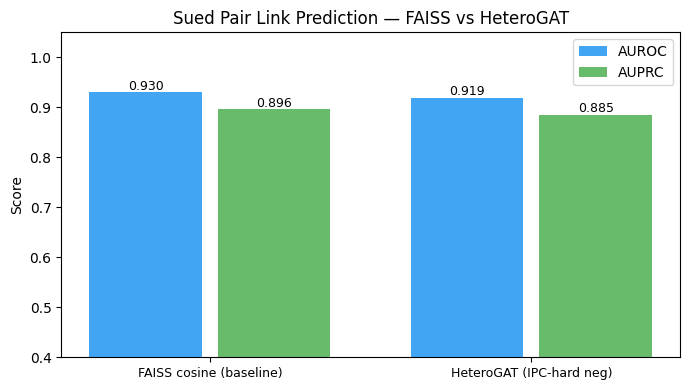

In [ ]:
# Cell 13 — Comparison: FAISS baseline vs HeteroGAT
faiss_auroc, faiss_auprc = faiss_baseline(test_edges)

results = [
    ('FAISS cosine (baseline)', faiss_auroc, faiss_auprc),
    ('HeteroGAT (IPC-hard neg)', te_auroc,   te_auprc),
]

print('=' * 52)
print(f'{"Model":<30} {"AUROC":>7}  {"AUPRC":>7}')
print('-' * 52)
for name, auroc, auprc in results:
    print(f'{name:<30} {auroc:>7.4f}  {auprc:>7.4f}')
print('=' * 52)

fig, ax = plt.subplots(figsize=(7, 4))
names  = [r[0] for r in results]
aurocs = [r[1] for r in results]
auprcs = [r[2] for r in results]
x = np.arange(len(names))
ax.bar(x - 0.2, aurocs, 0.35, label='AUROC', color='#2196F3', alpha=0.85)
ax.bar(x + 0.2, auprcs, 0.35, label='AUPRC', color='#4CAF50', alpha=0.85)
for i, (a, p) in enumerate(zip(aurocs, auprcs)):
    ax.text(i - 0.2, a + 0.005, f'{a:.3f}', ha='center', fontsize=9)
    ax.text(i + 0.2, p + 0.005, f'{p:.3f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(names, fontsize=9)
ax.set_ylim(0.4, 1.05)
ax.set_ylabel('Score')
ax.set_title('Sued Pair Link Prediction — FAISS vs HeteroGAT')
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
# Cell 14 — Embedding quality
@torch.no_grad()
def embedding_quality(model, hetero_data, edges, label=''):
    model.eval()
    h = model(hetero_data)['patent'].cpu().numpy()
    h = h / (np.linalg.norm(h, axis=1, keepdims=True) + 1e-8)

    src_e   = h[edges[0].numpy()]
    dst_e   = h[edges[1].numpy()]
    pos_sim = (src_e * dst_e).sum(1)

    rng_q   = np.random.default_rng(77)
    neg_idx = rng_q.integers(0, h.shape[0], len(pos_sim))
    neg_sim = (src_e * h[neg_idx]).sum(1)

    print(f'{label}')
    print(f'  Sued  pairs (pos): mean={pos_sim.mean():.4f}  std={pos_sim.std():.4f}')
    print(f'  Random pairs(neg): mean={neg_sim.mean():.4f}  std={neg_sim.std():.4f}')
    print(f'  Gap              : {pos_sim.mean() - neg_sim.mean():.4f}')
    return pos_sim, neg_sim

print('[FAISS baseline]')
src_r = pat_emb[test_edges[0].numpy()]
dst_r = pat_emb[test_edges[1].numpy()]
rng_f = np.random.default_rng(77)
neg_r = pat_emb[rng_f.integers(0, len(pat_list), len(src_r))]
print(f'  Sued  pairs (pos): mean={(src_r * dst_r).sum(1).mean():.4f}')
print(f'  Random pairs(neg): mean={(src_r * neg_r).sum(1).mean():.4f}')
print(f'  Gap              : {(src_r * dst_r).sum(1).mean() - (src_r * neg_r).sum(1).mean():.4f}')
print()
embedding_quality(model, data_d, test_edges, '[GNN]')

[FAISS baseline]
  Sued  pairs (pos): mean=0.6673
  Random pairs(neg): mean=0.5100
  Gap              : 0.1573

[GNN]
  Sued  pairs (pos): mean=0.7808  std=0.1550
  Random pairs(neg): mean=0.2971  std=0.2705
  Gap              : 0.4837


(array([0.80854475, 0.801202  , 0.86415935, 0.6274854 , 0.7779342 ,
        0.6905849 , 0.8687479 , 0.89129674, 0.683378  , 0.69096476,
        0.877542  , 0.8631436 , 0.8644082 , 0.9132316 , 0.8892561 ,
        0.7933583 , 0.71164894, 0.75219965, 0.9039241 , 0.8652073 ,
        0.73912525, 0.76831126, 0.64460135, 0.6560553 , 0.5795979 ,
        0.6363667 , 0.60716736, 0.5523955 , 0.88921   , 0.63634217,
        0.6836845 , 0.8142492 , 0.82107127, 0.8115251 , 0.78003395,
        0.7634703 , 0.78378475, 0.807883  , 0.8085234 , 0.71598965,
        0.7828745 , 0.7556139 , 0.7285728 , 0.9256826 , 0.9524537 ,
        0.93120515, 0.93645173, 0.6365094 , 0.6229715 , 0.8917448 ,
        0.8784884 , 0.7429881 , 0.93589735, 0.8933045 , 0.90523237,
        0.9271424 , 0.97178835, 0.8935499 , 0.82737434, 0.8238552 ,
        0.9795092 , 0.96892244, 0.8706212 , 0.79855436, 0.79994595,
        0.967067  , 0.97004294, 0.89690435, 0.81603277, 0.8273922 ,
        0.9802805 , 0.9703181 , 0.89590895, 0.81

In [ ]:
# Cell 15 — Per-case error analysis
@torch.no_grad()
def per_case_auroc(model, hetero_data, case_ids):
    model.eval()
    h = model(hetero_data)['patent']

    rows = []
    for case_id in sorted(case_ids):
        mask  = sued_cases == case_id
        if mask.sum() == 0: continue
        edges = sued_edges[:, mask]

        pos = F.cosine_similarity(h[edges[0].to(h.device)],
                                  h[edges[1].to(h.device)]).cpu().numpy()
        rng_c = np.random.default_rng(int(case_id) % 10000)
        neg_d = torch.tensor(rng_c.integers(0, len(pat_list), len(pos)),
                             dtype=torch.long).to(h.device)
        neg   = F.cosine_similarity(h[edges[0].to(h.device)], h[neg_d]).cpu().numpy()

        try:
            auroc = roc_auc_score(np.array([1]*len(pos)+[0]*len(neg)),
                                  np.concatenate([pos, neg]))
        except Exception:
            auroc = float('nan')

        rows.append({
            'case_row_id': case_id,
            'n_pairs'    : int(mask.sum()),
            'auroc'      : auroc,
            'pos_mean'   : float(pos.mean()),
            'neg_mean'   : float(neg.mean()),
            'gap'        : float(pos.mean() - neg.mean()),
        })
    return pd.DataFrame(rows).sort_values('auroc')

df_case_res = per_case_auroc(model, data_d, test_cases)
print(f'Per-case AUROC (test, {len(df_case_res)} cases):')
print(df_case_res.to_string(index=False))
print(f'\nMean AUROC : {df_case_res["auroc"].mean():.4f}')
print(f'Worst 5:')
print(df_case_res.head(5).to_string(index=False))

Per-case AUROC (test, 27 cases):
 case_row_id  n_pairs    auroc  pos_mean  neg_mean      gap
       56203        8 0.562500  0.377845  0.321954 0.055891
       15998        3 0.666667  0.785046  0.651694 0.133352
       14984        4 0.687500  0.806720  0.566881 0.239839
       14910        9 0.827160  0.653936  0.482511 0.171425
       66294       39 0.925049  0.702004  0.276495 0.425509
       14847       16 0.980469  0.817234  0.280106 0.537128
       52634       40 0.982500  0.896439  0.196146 0.700293
       56879        8 0.984375  0.876548  0.280039 0.596509
        1286        1 1.000000  0.808545  0.190979 0.617566
       17131        1 1.000000  0.808523  0.038322 0.770201
       33531        4 1.000000  0.936448  0.151799 0.784650
       20238        4 1.000000  0.745763  0.259196 0.486566
       36495        2 1.000000  0.629741  0.410483 0.219258
       14019        3 1.000000  0.698668  0.168586 0.530082
       11235        1 1.000000  0.801202 -0.183010 0.984212
       


  Ranking — FAISS baseline  (전체 1331개 특허 중 순위)
  평가 쌍: 165개
  MRR        : 0.1817
  Hits@1      : 0.0606  (10/165)
  Hits@5      : 0.3333  (55/165)
  Hits@10     : 0.5152  (85/165)
  Hits@50     : 0.6727  (111/165)
  Hits@100    : 0.7758  (128/165)
  Median rank: 10
  Mean rank  : 88.0

  Ranking — HeteroGAT  (전체 1331개 특허 중 순위)
  평가 쌍: 165개
  MRR        : 0.1271
  Hits@1      : 0.0364  (6/165)
  Hits@5      : 0.1879  (30/165)
  Hits@10     : 0.3394  (56/165)
  Hits@50     : 0.6727  (111/165)
  Hits@100    : 0.7636  (126/165)
  Median rank: 28
  Mean rank  : 77.6


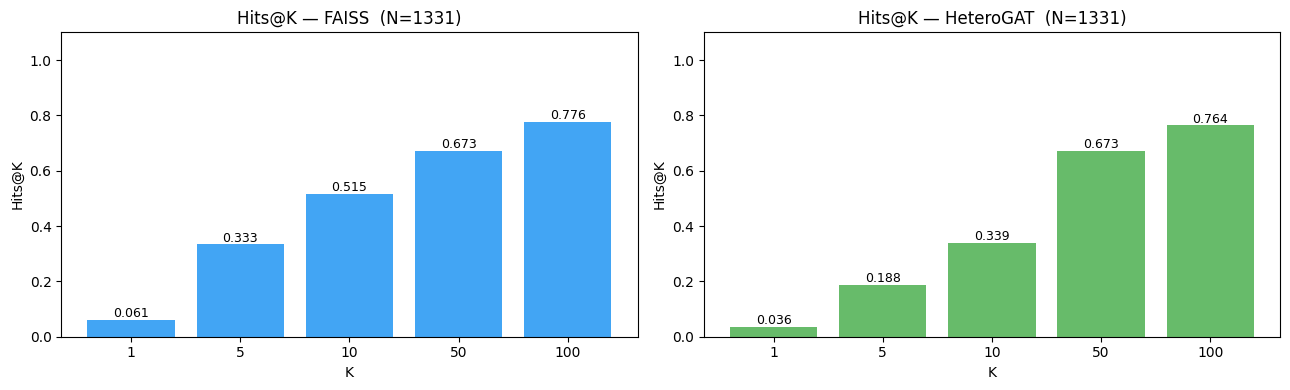

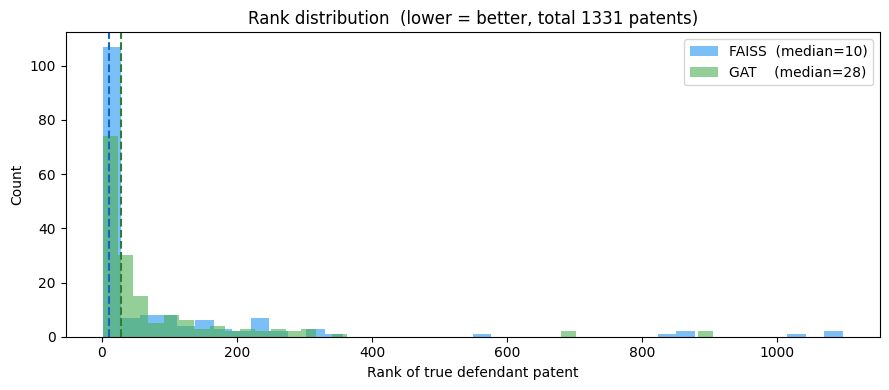

In [ ]:
# Cell 16 — Full ranking evaluation (Hits@K, MRR)
#
# 현재 AUROC: pos vs 랜덤 1개 비교 → "소송쌍이 랜덤보다 높은가?"
# Ranking eval: 원고특허 기준 전체 1,331개 랭킹 → "실제 피고특허가 몇 위인가?"

from collections import defaultdict

def _ranking_core(h_np, edges):
    """h_np: (N, D) L2-normalized, edges: [2, E] tensor"""
    src_ids = edges[0].numpy()
    dst_ids = edges[1].numpy()

    plt_to_defs = defaultdict(set)
    for s, d in zip(src_ids, dst_ids):
        plt_to_defs[s].add(d)

    ranks = []
    for plt_id, true_defs in plt_to_defs.items():
        sims           = h_np @ h_np[plt_id]
        sims[plt_id]   = -np.inf          # 자기 자신 제외
        order          = np.argsort(-sims)
        rank_of        = {int(pat): r + 1 for r, pat in enumerate(order)}
        for def_id in true_defs:
            ranks.append(rank_of[def_id])
    return np.array(ranks)

def print_ranking(ranks, label, N):
    print(f'\n{"=" * 54}')
    print(f'  Ranking — {label}  (전체 {N}개 특허 중 순위)')
    print(f'  평가 쌍: {len(ranks)}개')
    print(f'{"=" * 54}')
    print(f'  MRR        : {np.mean(1.0/ranks):.4f}')
    for k in [1, 5, 10, 50, 100]:
        h_ = np.mean(ranks <= k)
        print(f'  Hits@{k:<3}    : {h_:.4f}  ({int(h_*len(ranks))}/{len(ranks)})')
    print(f'  Median rank: {np.median(ranks):.0f}')
    print(f'  Mean rank  : {np.mean(ranks):.1f}')

N = len(pat_list)

# FAISS baseline ranking
faiss_ranks = _ranking_core(pat_emb, test_edges)
print_ranking(faiss_ranks, 'FAISS baseline', N)

# HeteroGAT ranking
with torch.no_grad():
    model.eval()
    h_gat = model(data_d)['patent']
    h_gat = F.normalize(h_gat, dim=1).cpu().numpy()
gnn_ranks = _ranking_core(h_gat, test_edges)
print_ranking(gnn_ranks, 'HeteroGAT', N)

# 시각화
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ks   = [1, 5, 10, 50, 100]
for ax, ranks, label, color in [
    (axes[0], faiss_ranks, 'FAISS', '#2196F3'),
    (axes[1], gnn_ranks,   'HeteroGAT', '#4CAF50'),
]:
    hits = [np.mean(ranks <= k) for k in ks]
    ax.bar([str(k) for k in ks], hits, color=color, alpha=0.85)
    for i, (k, h_) in enumerate(zip(ks, hits)):
        ax.text(i, h_ + 0.01, f'{h_:.3f}', ha='center', fontsize=9)
    ax.set_xlabel('K')
    ax.set_ylabel('Hits@K')
    ax.set_ylim(0, 1.1)
    ax.set_title(f'Hits@K — {label}  (N={N})')

plt.tight_layout(); plt.show()

# 랭킹 분포 비교
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(faiss_ranks, bins=40, alpha=0.6, label=f'FAISS  (median={np.median(faiss_ranks):.0f})', color='#2196F3')
ax.hist(gnn_ranks,   bins=40, alpha=0.6, label=f'GAT    (median={np.median(gnn_ranks):.0f})',   color='#4CAF50')
ax.axvline(np.median(faiss_ranks), color='#1565C0', linestyle='--')
ax.axvline(np.median(gnn_ranks),   color='#2E7D32', linestyle='--')
ax.set_xlabel('Rank of true defendant patent')
ax.set_ylabel('Count')
ax.set_title(f'Rank distribution  (lower = better, total {N} patents)')
ax.legend(); plt.tight_layout(); plt.show()